# Reto S12 · «Escuchar al cliente» · ocupación · equipo «Las Palmeras» (entrega de referencia)

**Pregunta del cliente:** *¿cuánta ocupación habrá la semana que viene?*

**Qué hace:** parte la serie **por fecha** (entrena con lo antiguo y evalúa con los últimos 91 días, sin barajar), calcula los *baselines* («igual que ayer», «igual que la semana anterior», «media de las 4 últimas semanas»), entrena un SARIMAX con festivos y estacionalidad anual, entrena una red GRU como alternativa, los pone **en la misma tabla de MAE** y da la previsión de los próximos 7 días y una frase para el cliente.

**Cómo se ejecuta:** *Entorno de ejecución → Reiniciar y ejecutar todo* (un par de minutos). `SEMILLA = 42` (la GRU usa 42, 43 y 44).

**Sin fuga de datos:** el escalado de la GRU (media y desviación) y los parámetros del SARIMAX se calculan **solo con el entrenamiento**; las variables de calendario no dependen de los datos. Las ventanas de entrenamiento de la GRU terminan donde empieza la prueba.

## 0. Preparación

In [1]:
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
print("Listo ✔")

Listo ✔


## 1. Los datos y la partición por fecha

In [2]:
ocup = pd.read_csv(dato("ocupacion_diaria.csv"), parse_dates=["fecha"]).set_index("fecha")
ocup.index.freq = "D"
serie = ocup["ocupacion_pct"]
print(ocup.shape, "días:", serie.index.min().date(), "→", serie.index.max().date())

DIAS_TEST = 91
entrenamiento, prueba = serie.iloc[:-DIAS_TEST], serie.iloc[-DIAS_TEST:]
print("Entrenamiento:", entrenamiento.index.min().date(), "→", entrenamiento.index.max().date(), f"({len(entrenamiento)} días)")
print("Prueba       :", prueba.index.min().date(), "→", prueba.index.max().date(), f"({len(prueba)} días)")
assert entrenamiento.index.max() < prueba.index.min(), "La prueba es siempre posterior al entrenamiento (la serie no se baraja)."
print("✔ Partición por fecha: todo lo de prueba es posterior al entrenamiento")

(1096, 4) días: 2023-01-01 → 2025-12-31
Entrenamiento: 2023-01-01 → 2025-10-01 (1005 días)
Prueba       : 2025-10-02 → 2025-12-31 (91 días)
✔ Partición por fecha: todo lo de prueba es posterior al entrenamiento


## 2. *Baselines*: los métodos simples que hay que batir
Una previsión por semana de prueba, con la historia que había hasta ese lunes.

In [3]:
HORIZONTE = 7
origenes = [o for o in range(len(entrenamiento), len(serie), HORIZONTE) if o + HORIZONTE <= len(serie)]   # una previsión por semana de prueba

def mae(real, pred):
    return float(np.mean(np.abs(np.asarray(real) - np.asarray(pred))))

def evaluar_semanal(predictor):
    """predictor(historia, origen) -> 7 valores. Devuelve (MAE, predicciones concatenadas)."""
    preds, reales = [], []
    for o in origenes:
        preds.append(np.asarray(predictor(serie.iloc[:o], o)))
        reales.append(serie.iloc[o:o + HORIZONTE].values)
    preds, reales = np.concatenate(preds), np.concatenate(reales)
    return mae(reales, preds), preds

def pred_ingenuo(historia, o):
    return np.repeat(historia.iloc[-1], HORIZONTE)

def pred_estacional(historia, o):                  # «igual que la semana anterior»
    return historia.iloc[-7:].values

def pred_media4(historia, o):
    return historia.iloc[-28:].values.reshape(4, 7).mean(axis=0)

mae_ing, p_ing = evaluar_semanal(pred_ingenuo)
mae_est, p_est = evaluar_semanal(pred_estacional)
mae_media4, p_media4 = evaluar_semanal(pred_media4)
print(f"{len(origenes)} semanas de prueba, {len(origenes) * HORIZONTE} días")
print(f"MAE ingenuo (igual que ayer)           : {mae_ing:.2f} puntos de ocupación")
print(f"MAE estacional (igual que la semana pasada): {mae_est:.2f}")
print(f"MAE media de 4 semanas                 : {mae_media4:.2f}")
assert len(pred_media4(serie.iloc[:400], 400)) == 7
print("✔ Baselines calculados con su MAE")

13 semanas de prueba, 91 días
MAE ingenuo (igual que ayer)           : 5.95 puntos de ocupación
MAE estacional (igual que la semana pasada): 4.46
MAE media de 4 semanas                 : 4.45
✔ Baselines calculados con su MAE


## 3. SARIMAX con festivos y estacionalidad anual
Se ajusta con el entrenamiento; en la prueba solo se **aplica** (`refit=False`) a la historia disponible cada semana.

In [4]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

def exogenas(indice):
    """Fourier anual (2 armónicos) y festivo. En fechas futuras el festivo es el del mismo día del año anterior (son fechas fijas)."""
    dia_anio = indice.dayofyear.values
    X = pd.DataFrame(index=indice)
    for k in (1, 2):
        X[f"sin{k}"] = np.sin(2 * np.pi * k * dia_anio / 365.25)
        X[f"cos{k}"] = np.cos(2 * np.pi * k * dia_anio / 365.25)
    X["festivo"] = [ocup["festivo"].get(d, ocup["festivo"].get(d - pd.DateOffset(years=1), 0)) for d in indice]
    return X

X_todo = exogenas(serie.index)
X_ent = X_todo.iloc[:-DIAS_TEST]
ORDEN_SARIMAX = dict(order=(1, 0, 1), seasonal_order=(1, 1, 1, 7), enforce_stationarity=False, enforce_invertibility=False)

res = SARIMAX(entrenamiento, exog=X_ent, **ORDEN_SARIMAX).fit(disp=False, maxiter=200)      # solo con el entrenamiento
def pred_sarimax(historia, o):
    r = res.apply(historia, exog=X_todo.iloc[:o], refit=False)
    return r.forecast(HORIZONTE, exog=X_todo.iloc[o:o + HORIZONTE]).values
mae_sar, p_sar = evaluar_semanal(pred_sarimax)

res2 = SARIMAX(entrenamiento, **ORDEN_SARIMAX).fit(disp=False, maxiter=200)
def pred_sarimax_simple(historia, o):
    return res2.apply(historia, refit=False).forecast(HORIZONTE).values
mae_sin_exog, _ = evaluar_semanal(pred_sarimax_simple)
print(f"MAE SARIMAX con festivos y Fourier: {mae_sar:.2f}")
print(f"MAE SARIMAX sin variables externas: {mae_sin_exog:.2f}")
print("Coeficientes (festivo):", round(float(res.params["festivo"]), 2), "puntos de ocupación en festivo")

MAE SARIMAX con festivos y Fourier: 3.18
MAE SARIMAX sin variables externas: 3.93
Coeficientes (festivo): 9.21 puntos de ocupación en festivo


## 4. Alternativa: red GRU
Ventana de 28 días → los 7 siguientes. Tres semillas porque una red cambia de una ejecución a otra.

In [5]:
import tensorflow as tf
from tensorflow import keras
tf.config.experimental.enable_op_determinism()

VENTANA = 28
media_ent, desv_ent = float(entrenamiento.mean()), float(entrenamiento.std())      # el escalado se ajusta SOLO con el entrenamiento
dia_semana = serie.index.dayofweek.values
F = np.column_stack([(serie.values - media_ent) / desv_ent, np.sin(2 * np.pi * dia_semana / 7), np.cos(2 * np.pi * dia_semana / 7)]).astype("float32")

def ventanas(hasta):
    Xs, ys = [], []
    for e in range(VENTANA, hasta - HORIZONTE + 1):
        Xs.append(F[e - VENTANA:e]); ys.append(F[e:e + HORIZONTE, 0])
    return np.array(Xs), np.array(ys)

X_gru, y_gru = ventanas(len(entrenamiento))          # ninguna ventana llega a la prueba
print("Ventanas de entrenamiento:", X_gru.shape, "→", y_gru.shape)

def entrenar_gru(semilla):
    keras.utils.set_random_seed(semilla)
    m = keras.Sequential([keras.layers.Input((VENTANA, 3)), keras.layers.GRU(32), keras.layers.Dense(HORIZONTE)])
    m.compile(optimizer=keras.optimizers.Adam(0.003), loss="mae")
    m.fit(X_gru, y_gru, validation_split=0.15, epochs=60, batch_size=32, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)])
    return m

def predictor_gru(m):
    def pred(historia, o):
        return m.predict(F[o - VENTANA:o][None], verbose=0)[0] * desv_ent + media_ent
    return pred

SEMILLAS_GRU = (42, 43, 44)
modelos_gru = [entrenar_gru(s) for s in SEMILLAS_GRU]
maes_gru = []
preds_gru = []
for m in modelos_gru:
    e, p = evaluar_semanal(predictor_gru(m))
    maes_gru.append(e); preds_gru.append(p)
mae_gru = float(np.mean(maes_gru))
print("MAE de la GRU por semilla:", [round(e, 2) for e in maes_gru], f"· media {mae_gru:.2f}")

I0000 00:00:1794908084.284475   15520 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794908084.350028   15520 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794908085.441638   15520 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Ventanas de entrenamiento: (971, 28, 3) → (971, 7)


E0000 00:00:1794908085.838607   15520 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1794908093.384016   15520 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1794908099.184088   15520 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1794908104.544184   15520 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


MAE de la GRU por semilla: [4.12, 4.2, 4.31] · media 4.21


## 5. Todo en la misma tabla y veredicto

In [6]:
comparativa = pd.Series({"Ingenuo (igual que ayer)": mae_ing, "Estacional (igual que la semana pasada)": mae_est,
                         "Media de 4 semanas": mae_media4, "SARIMAX sin variables externas": mae_sin_exog,
                         "SARIMAX + festivos + Fourier": mae_sar, "GRU (media de 3 semillas)": mae_gru}).sort_values()
print("MAE a 7 días en la prueba (puntos de ocupación, menos es mejor):")
print(comparativa.round(2).to_string())

mejor_baseline_nombre = min({"Ingenuo": mae_ing, "Estacional": mae_est, "Media de 4 semanas": mae_media4}.items(), key=lambda kv: kv[1])
mejor_baseline = mejor_baseline_nombre[1]
modelos = {"SARIMAX + festivos + Fourier": mae_sar, "GRU (media de 3 semillas)": mae_gru}
elegido = min(modelos, key=modelos.get)
mejora_pct = round(100 * (mejor_baseline - modelos[elegido]) / mejor_baseline, 1)
gana = modelos[elegido] < mejor_baseline
print(f"\nMejor baseline: {mejor_baseline_nombre[0]} ({mejor_baseline:.2f}). Mejor modelo: {elegido} ({modelos[elegido]:.2f}).")
print("Veredicto:", f"el modelo gana al mejor baseline por un {mejora_pct} %." if gana else
      f"el modelo NO gana al mejor baseline ({mejora_pct} %): recomendamos el baseline.")
print(f"SARIMAX frente a GRU: {mae_sar:.2f} frente a {mae_gru:.2f} (diferencia {abs(mae_sar - mae_gru):.2f} puntos; las 3 semillas de la GRU varían {max(maes_gru) - min(maes_gru):.2f}).")

MAE a 7 días en la prueba (puntos de ocupación, menos es mejor):
SARIMAX + festivos + Fourier               3.18
SARIMAX sin variables externas             3.93
GRU (media de 3 semillas)                  4.21
Media de 4 semanas                         4.45
Estacional (igual que la semana pasada)    4.46
Ingenuo (igual que ayer)                   5.95

Mejor baseline: Media de 4 semanas (4.45). Mejor modelo: SARIMAX + festivos + Fourier (3.18).
Veredicto: el modelo gana al mejor baseline por un 28.5 %.
SARIMAX frente a GRU: 3.18 frente a 4.21 (diferencia 1.03 puntos; las 3 semillas de la GRU varían 0.19).


## 6. Previsión de la semana siguiente

      día  igual que la semana pasada  SARIMAX       GRU
Thu 01/01                        85.7     83.8 81.099998
Fri 02/01                        94.2     93.0 85.599998
Sat 03/01                        92.3     93.3 88.099998
Sun 04/01                        92.2     93.1 85.500000
Mon 05/01                        74.9     84.6 80.099998
Tue 06/01                        83.3     84.2 76.900002
Wed 07/01                        80.6     76.4 77.099998


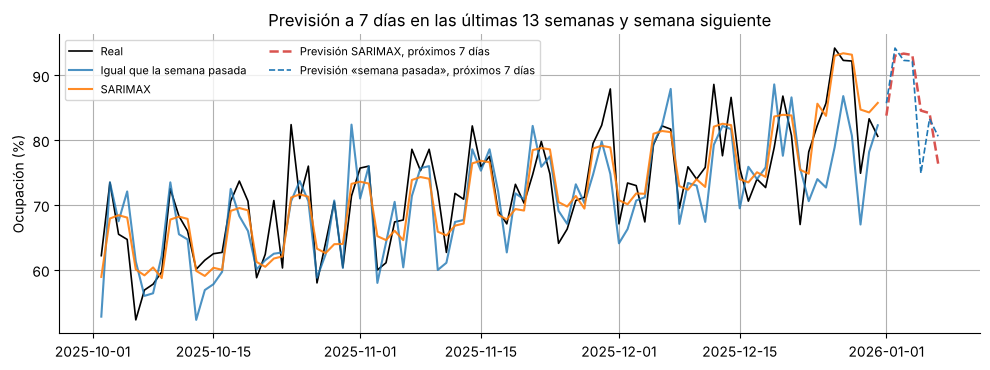

In [7]:
# Previsión de los 7 días siguientes al final de la serie (los parámetros siguen siendo los del entrenamiento)
futuro = pd.date_range(serie.index[-1] + pd.Timedelta(days=1), periods=HORIZONTE, freq="D")
prev_sarimax = res.apply(serie, exog=X_todo, refit=False).forecast(HORIZONTE, exog=exogenas(futuro)).values
prev_estacional = serie.iloc[-7:].values
prev_gru = predictor_gru(modelos_gru[0])(serie, len(serie))
tabla_futuro = pd.DataFrame({"día": futuro.strftime("%a %d/%m"), "igual que la semana pasada": prev_estacional.round(1),
                             "SARIMAX": prev_sarimax.round(1), "GRU": prev_gru.round(1)})
print(tabla_futuro.to_string(index=False))

n = len(p_sar); ind = serie.index[origenes[0]:origenes[0] + n]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(prueba.index, prueba.values, label="Real", color="black", lw=1.2)
ax.plot(ind, p_est, label="Igual que la semana pasada", alpha=.8)
ax.plot(ind, p_sar, label="SARIMAX", alpha=.9)
ax.plot(futuro, prev_sarimax, "--", color="#d9534f", label="Previsión SARIMAX, próximos 7 días", lw=1.8)
ax.plot(futuro, prev_estacional, "--", color="#1f77b4", label="Previsión «semana pasada», próximos 7 días", lw=1.2)
ax.set_title("Previsión a 7 días en las últimas 13 semanas y semana siguiente"); ax.set_ylabel("Ocupación (%)"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

## 7. Una frase para el cliente

In [8]:
error_relativo = round(100 * modelos[elegido] / float(prueba.mean()), 1)
if gana:
    frase_cliente = (f"La previsión de ocupación a 7 días se equivoca de media {modelos[elegido]:.1f} puntos de ocupación "
                     f"(un {error_relativo} % de la ocupación media), un {mejora_pct} % menos que repetir la semana anterior ({mae_est:.1f} puntos).")
else:
    frase_cliente = (f"El modelo no mejora a repetir la semana anterior, que se equivoca de media {mejor_baseline:.1f} puntos de ocupación "
                     f"(un {round(100 * mejor_baseline / float(prueba.mean()), 1)} % de la ocupación media): recomendamos usar ese método simple.")
print("Frase para el cliente:", frase_cliente)

Frase para el cliente: La previsión de ocupación a 7 días se equivoca de media 3.2 puntos de ocupación (un 4.4 % de la ocupación media), un 28.5 % menos que repetir la semana anterior (4.5 puntos).


## 8. Cifras para el informe y versiones

In [9]:
import json, sys, statsmodels, sklearn
cifras = {
    "dias_test": DIAS_TEST, "semanas_test": len(origenes), "media_prueba": round(float(prueba.mean()), 1),
    "entrenamiento": [str(entrenamiento.index.min().date()), str(entrenamiento.index.max().date())],
    "prueba": [str(prueba.index.min().date()), str(prueba.index.max().date())],
    "mae": {k: round(float(v), 2) for k, v in comparativa.items()},
    "maes_gru": [round(e, 2) for e in maes_gru], "mejor_baseline": [mejor_baseline_nombre[0], round(mejor_baseline, 2)],
    "elegido": elegido, "mae_elegido": round(modelos[elegido], 2), "mejora_pct": mejora_pct, "gana": bool(gana),
    "mae_sar": round(mae_sar, 2), "mae_gru": round(mae_gru, 2), "mae_est": round(mae_est, 2),
    "error_relativo": error_relativo, "frase_cliente": frase_cliente,
    "futuro": [{"dia": str(d.date()), "semana_pasada": round(float(a), 1), "sarimax": round(float(b), 1), "gru": round(float(c), 1)}
               for d, a, b, c in zip(futuro, prev_estacional, prev_sarimax, prev_gru)],
    "festivo_coef": round(float(res.params["festivo"]), 2),
    "versiones": f"Python {sys.version.split()[0]}, numpy {np.__version__}, pandas {pd.__version__}, statsmodels {statsmodels.__version__}, tensorflow {tf.__version__}",
}
print(json.dumps(cifras, ensure_ascii=False))

{"dias_test": 91, "semanas_test": 13, "media_prueba": 72.5, "entrenamiento": ["2023-01-01", "2025-10-01"], "prueba": ["2025-10-02", "2025-12-31"], "mae": {"SARIMAX + festivos + Fourier": 3.18, "SARIMAX sin variables externas": 3.93, "GRU (media de 3 semillas)": 4.21, "Media de 4 semanas": 4.45, "Estacional (igual que la semana pasada)": 4.46, "Ingenuo (igual que ayer)": 5.95}, "maes_gru": [4.12, 4.2, 4.31], "mejor_baseline": ["Media de 4 semanas", 4.45], "elegido": "SARIMAX + festivos + Fourier", "mae_elegido": 3.18, "mejora_pct": 28.5, "gana": true, "mae_sar": 3.18, "mae_gru": 4.21, "mae_est": 4.46, "error_relativo": 4.4, "frase_cliente": "La previsión de ocupación a 7 días se equivoca de media 3.2 puntos de ocupación (un 4.4 % de la ocupación media), un 28.5 % menos que repetir la semana anterior (4.5 puntos).", "futuro": [{"dia": "2026-01-01", "semana_pasada": 85.7, "sarimax": 83.8, "gru": 81.1}, {"dia": "2026-01-02", "semana_pasada": 94.2, "sarimax": 93.0, "gru": 85.6}, {"dia": "20